# კვირა VI: მრავალშრიანი ქსელი (Multi-Layer Network / MLP)
**კურსი:** ხელოვნური ინტელექტი და მანქანური სწავლების საწყისები (BTU)  
**სახელმძღვანელო:** Chris Albon, *Machine Learning with Python Cookbook* (Recipes 4.2, 11.1, 11.3, 12.3, 20.1–20.3)  
**მთავარი კითხვა:** რატომ არ ჰყოფნის ერთი ნეირონი?

---
### 🎯 დღევანდელი პრაქტიკის 3 ნაბიჯი:
1. **XOR-ის პრობლემა (`# TODO 1`):** წინა კვირის `Perceptron` (1 სწორი ხაზი) vs მრავალშრიანი ქსელი `MLPClassifier` (ფარული შრეები + `ReLU` აქტივაცია).
2. **`Pipeline(StandardScaler -> MLP)` IV კვირის ამოცანაზე (`# TODO 2`):** რეალური მონაცემების (`Adult Census Income`) მომზადება და ნეირონული ქსელის ჩასმა ერთიან მილსადენში.
3. **დიდი დუელი (`# TODO 3`):** `MLP` მილსადენისა და IV კვირის `kNN` მილსადენის სამართლიანი შედარება იმავე 5-Fold კროს-ვალიდაციით ($F_1$ ქულა და პროგნოზირების სისწრაფე).

In [1]:
import time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Perceptron
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import f1_score, classification_report

print("ბიბლიოთეკები მზადაა!")

ბიბლიოთეკები მზადაა!


## 1. XOR-ის პრობლემა: რატომ მარცხდება ერთი ნეირონი? (Recipe 20.2)

**XOR (გამომრიცხავი „ან“)** ამოცანაში კლასი $1$ ინთება მხოლოდ მაშინ, როცა ორი ჩამრთველი **განსხვავებულ** პოზიციაშია:
* **კლასი 0 (წითელი):** $(0, 0)$ და $(1, 1)$
  
* **კლასი 1 (მწვანე):** $(0, 1)$ და $(1, 0)$

წინა კვირის **პერცეპტრონს** ($z = w_1 x_1 + w_2 x_2 + b$) გეომეტრიულად შეუძლია მხოლოდ **ერთი სწორი წრფის** გავლება.  
სამაგიეროდ, **მრავალშრიანი ქსელი (`MLPClassifier`)** იყენებს **ფარულ შრეებს (Hidden Layers)** და არაწრფივ **ReLU** აქტივაციას:
$$\text{ReLU}(z) = \max(0, z)$$
რაც ქსელს საშუალებას აძლევს „გადაკეცოს“ სივრცე და გაავლოს არაწრფივი გამყოფი საზღვარი!

**✍️ დავალება 1 (`# TODO 1`):** გაწვრთნეთ `Perceptron` და `MLPClassifier(hidden_layer_sizes=(8, 8), activation="relu")` XOR მონაცემებზე.

Perceptron (1 ნეირონი, წრფივი) სიზუსტე XOR-ზე : 64.0%
MLPClassifier (ფარული შრეები + ReLU) სიზუსტე : 100.0%


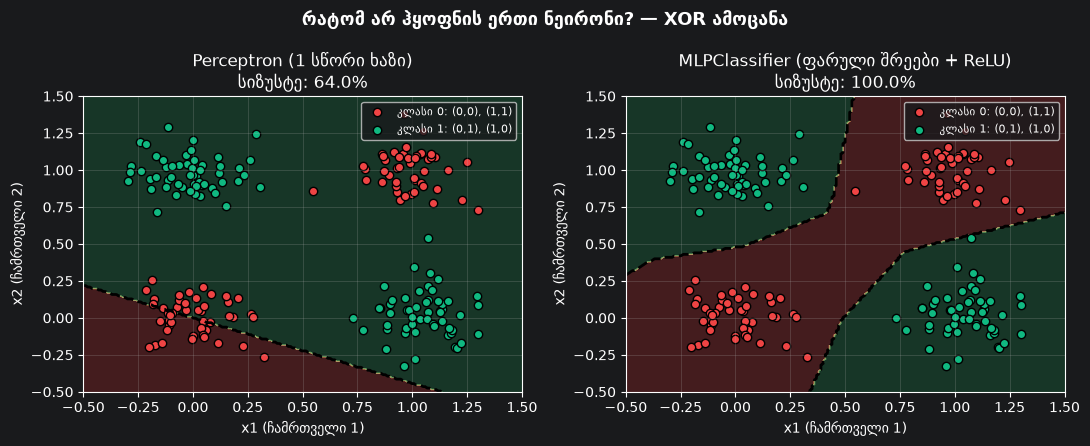

In [2]:
# შევქმნათ 2D XOR მონაცემები (200 წერტილი 4 კუთხის გარშემო):
rng = np.random.RandomState(42)
centers = np.array([[0, 0], [1, 1], [0, 1], [1, 0]])
labels = np.array([0, 0, 1, 1])
idx = rng.choice(4, size=200)
X_xor = centers[idx] + rng.normal(scale=0.14, size=(200, 2))
y_xor = labels[idx]

# TODO 1a: შექმენით და გაწვრთნეთ წრფივი Perceptron:
perc = Perceptron(max_iter=1000, random_state=42)
perc.fit(X_xor, y_xor)

# TODO 1b: შექმენით და გაწვრთნეთ MLPClassifier 2 ფარული შრით (8, 8) და ReLU აქტივაციით:
mlp_xor = MLPClassifier(hidden_layer_sizes=(8, 8), activation="relu", max_iter=1000, random_state=42)
mlp_xor.fit(X_xor, y_xor)

acc_perc = perc.score(X_xor, y_xor)
acc_mlp = mlp_xor.score(X_xor, y_xor)
print(f"Perceptron (1 ნეირონი, წრფივი) სიზუსტე XOR-ზე : {acc_perc:.1%}")
print(f"MLPClassifier (ფარული შრეები + ReLU) სიზუსტე : {acc_mlp:.1%}")

# გადაწყვეტილების საზღვრების (Decision Boundaries) გვერდიგვერდ დახატვა:
xx, yy = np.meshgrid(np.linspace(-0.5, 1.5, 200), np.linspace(-0.5, 1.5, 200))
grid_points = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, model, title in [
    (axes[0], perc, f"Perceptron (1 სწორი ხაზი)\nსიზუსტე: {acc_perc:.1%}"),
    (axes[1], mlp_xor, f"MLPClassifier (ფარული შრეები + ReLU)\nსიზუსტე: {acc_mlp:.1%}")
]:
    Z = model.predict(grid_points).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap="RdYlGn")
    ax.contour(xx, yy, Z, levels=[0.5], colors="k", linewidths=2, linestyles="--")
    ax.scatter(X_xor[y_xor == 0, 0], X_xor[y_xor == 0, 1], c="#ef4444", edgecolor="k", label="კლასი 0: (0,0), (1,1)")
    ax.scatter(X_xor[y_xor == 1, 0], X_xor[y_xor == 1, 1], c="#10b981", edgecolor="k", label="კლასი 1: (0,1), (1,0)")
    ax.set_title(title)
    ax.set_xlabel("x1 (ჩამრთველი 1)")
    ax.set_ylabel("x2 (ჩამრთველი 2)")
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(True, alpha=0.3)

plt.suptitle("რატომ არ ჰყოფნის ერთი ნეირონი? — XOR ამოცანა", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

### 🔍 რას ვხედავთ გრაფიკზე?
* **მარცხენა გრაფიკი (`Perceptron`):** ერთი ნეირონი ახერხებს მხოლოდ ერთი სწორი წყვეტილი ხაზის გავლებას, ამიტომ დიაგონალზე განლაგებულ კლასებს ვერ აცალკევებს.
* **მარჯვენა გრაფიკი (`MLPClassifier`):** ფარულმა შრეებმა და `ReLU` აქტივაციამ სივრცე „მოხარეს“ და ორივე დიაგონალური კლასი იდეალურად გამოყვეს!

---
## 2. IV კვირის რეალური ამოცანა (`Adult Census Income`) — მონაცემების მომზადება

ახლა გამოვცადოთ მრავალშრიანი ქსელი IV კვირის რეალურ ამოცანაზე: ვიწინასწარმეტყველოთ, აღემატება თუ არა ადამიანის წლიური შემოსავალი **$50,000-ს**.  
იმისათვის, რომ შედარება IV კვირის `kNN` მოდელთან **100%-ით სამართლიანი** იყოს, ვიყენებთ:
1. ზუსტად იმავე `train_test_split(..., test_size=0.2, stratify=y, random_state=42)` გაყოფას;
2. ზუსტად იმავე 5-Fold კროს-ვალიდაციის სქემას: `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`;
3. ზუსტად იმავე `ColumnTransformer`-ს (`SimpleImputer` + `StandardScaler` რიცხვით სვეტებზე, `SimpleImputer` + `OneHotEncoder` კატეგორიულ სვეტებზე).

In [3]:
print("Adult Census მონაცემების ჩატვირთვა...")
df = fetch_openml("adult", version=2, as_frame=True).frame

X = df.drop(columns=["fnlwgt", "education", "class"])
y = (df["class"] == ">50K").astype(int)

NUMERIC_COLS = X.select_dtypes(include="number").columns.tolist()
CATEGORICAL_COLS = X.select_dtypes(exclude="number").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# მონაცემთა მომზადების კონვეიერი (Recipe 4.2, 12.3, 20.1):
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])
preprocessor = ColumnTransformer([
    ("num", num_pipe, NUMERIC_COLS),
    ("cat", cat_pipe, CATEGORICAL_COLS)
])

print(f"Train: {X_train.shape}, Test: {X_test.shape} | Preprocessor მზადაა!")

Adult Census მონაცემების ჩატვირთვა...
Train: (39073, 12), Test: (9769, 12) | Preprocessor მზადაა!


### `Pipeline(Prep -> MLP)` აწყობა (Recipe 20.1 & 20.3)

რატომ არის `StandardScaler` (`preprocessor`-ის შიგნით) სასიცოცხლოდ აუცილებელი `MLPClassifier`-ის წინ?  
იმიტომ, რომ სტანდარტიზაციის გარეშე დიდი მასშტაბის სვეტები (მაგ. `capital-gain` $= 99,999$) გამოიწვევს გიგანტურ შეწონილ ჯამებს და Backpropagation-ის გრადიენტებს აურევს!

**✍️ დავალება 2 (`# TODO 2`):** ააწყვეთ `mlp_pipe`, სადაც `("prep", preprocessor)`-ის შემდეგ დგას `MLPClassifier` ორი ფარული შრით `(32, 16)` და `ReLU` აქტივაციით.

In [4]:
# ა) IV კვირის საბაზისო kNN მილსადენი:
knn_pipe = Pipeline([
    ("prep", preprocessor),
    ("pca", PCA(n_components=10, random_state=42)),
    ("knn", KNeighborsClassifier(n_neighbors=15))
])

# ბ) TODO 2: ააწყვეთ VI კვირის მრავალშრიანი ქსელის (MLP) მილსადენი:
mlp_pipe = Pipeline([
    ("prep", preprocessor),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        max_iter=50,
        early_stopping=True,
        random_state=42
    ))
])

print("ორივე მილსადენი (knn_pipe და mlp_pipe) მზადაა დუელისთვის!")

ორივე მილსადენი (knn_pipe და mlp_pipe) მზადაა დუელისთვის!


---
## 3. დუელი: `MLP Pipeline` vs IV კვირის `kNN Pipeline` (Recipe 11.1 & 11.3)

**✍️ დავალება 3 (`# TODO 3`):**
1. შეაფასეთ ორივე მილსადენი სასწავლო მონაცემებზე იმავე 5-Fold კროს-ვალიდაციით (`cv=cv, scoring="f1"`).
2. გაწვრთნეთ ორივე მოდელი სრულ `X_train`-ზე და შეადარეთ სატესტო $F_1$ ქულა და **პროგნოზირების სისწრაფე (`predict` დრო)** `X_test`-ზე!

In [5]:
print("მიმდინარეობს 5-Fold კროს-ვალიდაცია (დაახლოებით 15-20 წამი)...")

# TODO 3: გამოთვალეთ 5-Fold CV F1 ქულის საშუალო ორივე მილსადენისთვის:
f1_knn_cv = cross_val_score(knn_pipe, X_train, y_train, cv=cv, scoring="f1").mean()
f1_mlp_cv = cross_val_score(mlp_pipe, X_train, y_train, cv=cv, scoring="f1").mean()

print(f"IV კვირის kNN Pipeline (5-Fold CV F1) : {f1_knn_cv:.3f}")
print(f"VI კვირის MLP Pipeline (5-Fold CV F1) : {f1_mlp_cv:.3f}  (სხვაობა: +{f1_mlp_cv - f1_knn_cv:.3f})\n")

# გავწვრთნათ ორივე მილსადენი სრულ სასწავლო მონაცემებზე:
knn_pipe.fit(X_train, y_train)
mlp_pipe.fit(X_train, y_train)

# გავზომოთ პროგნოზირების (predict) სისწრაფე სატესტო შერჩევაზე (9,769 ადამიანი):
t0 = time.perf_counter()
y_pred_knn = knn_pipe.predict(X_test)
t_pred_knn = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred_mlp = mlp_pipe.predict(X_test)
t_pred_mlp = time.perf_counter() - t0

f1_knn_test = f1_score(y_test, y_pred_knn)
f1_mlp_test = f1_score(y_test, y_pred_mlp)

print("--- სატესტო შედეგების შედარება (X_test = 9,769 ჩანაწერი) ---")
print(f"kNN Pipeline -> Test F1: {f1_knn_test:.3f} | პროგნოზირების დრო (predict): {t_pred_knn:.3f} წმ")
print(f"MLP Pipeline -> Test F1: {f1_mlp_test:.3f} | პროგნოზირების დრო (predict): {t_pred_mlp:.3f} წმ")
print(f"-> MLP პროგნოზირებისას {t_pred_knn / max(t_pred_mlp, 1e-6):.1f}x-ჯერ უფრო სწრაფია!\n")

print("--- MLP Pipeline: დეტალური სატესტო რეპორტი ---")
print(classification_report(y_test, y_pred_mlp, target_names=["<=50K", ">50K"]))

მიმდინარეობს 5-Fold კროს-ვალიდაცია (დაახლოებით 15-20 წამი)...
IV კვირის kNN Pipeline (5-Fold CV F1) : 0.649
VI კვირის MLP Pipeline (5-Fold CV F1) : 0.674  (სხვაობა: +0.025)

--- სატესტო შედეგების შედარება (X_test = 9,769 ჩანაწერი) ---
kNN Pipeline -> Test F1: 0.652 | პროგნოზირების დრო (predict): 0.490 წმ
MLP Pipeline -> Test F1: 0.675 | პროგნოზირების დრო (predict): 0.022 წმ
-> MLP პროგნოზირებისას 21.8x-ჯერ უფრო სწრაფია!

--- MLP Pipeline: დეტალური სატესტო რეპორტი ---
              precision    recall  f1-score   support

       <=50K       0.89      0.93      0.91      7431
        >50K       0.74      0.62      0.67      2338

    accuracy                           0.86      9769
   macro avg       0.81      0.78      0.79      9769
weighted avg       0.85      0.86      0.85      9769



## 4. ვიზუალიზაცია: Backpropagation-ის სწავლის მრუდი (`loss_curve_`) და მოდელების შედარება

ვნახოთ, როგორ მცირდებოდა მრავალშრიანი ქსელის შეცდომა (Loss) ეპოქიდან ეპოქამდე Backpropagation-ის წყალობით, და შევადაროთ საბოლოო $F_1$ ქულები.

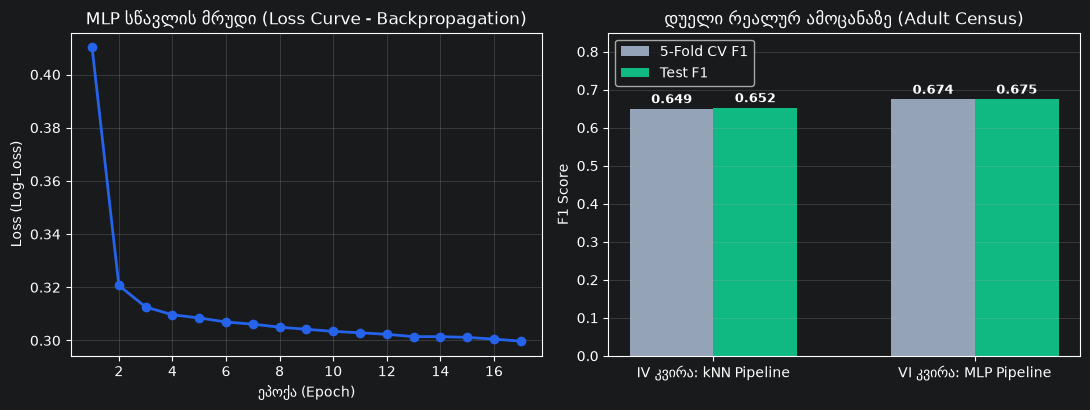

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

# გრაფიკი 1: MLP-ის სწავლის მრუდი (Loss Curve)
loss_curve = mlp_pipe.named_steps["mlp"].loss_curve_
axes[0].plot(range(1, len(loss_curve) + 1), loss_curve, marker="o", color="#2563eb", linewidth=2)
axes[0].set_title("MLP სწავლის მრუდი (Loss Curve - Backpropagation)")
axes[0].set_xlabel("ეპოქა (Epoch)")
axes[0].set_ylabel("Loss (Log-Loss)")
axes[0].grid(True, alpha=0.3)

# გრაფიკი 2: kNN vs MLP F1 ქულების შედარება
x_pos = np.arange(2)
width = 0.32
axes[1].bar(x_pos - width / 2, [f1_knn_cv, f1_mlp_cv], width, label="5-Fold CV F1", color="#94a3b8")
axes[1].bar(x_pos + width / 2, [f1_knn_test, f1_mlp_test], width, label="Test F1", color="#10b981")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(["IV კვირა: kNN Pipeline", "VI კვირა: MLP Pipeline"])
axes[1].set_ylim(0, 0.85)
axes[1].set_ylabel("F1 Score")
axes[1].set_title("დუელი რეალურ ამოცანაზე (Adult Census)")
for i, (cv_val, test_val) in enumerate(zip([f1_knn_cv, f1_mlp_cv], [f1_knn_test, f1_mlp_test])):
    axes[1].text(i - width / 2, cv_val + 0.015, f"{cv_val:.3f}", ha="center", fontsize=9, fontweight="bold")
    axes[1].text(i + width / 2, test_val + 0.015, f"{test_val:.3f}", ha="center", fontsize=9, fontweight="bold")
axes[1].legend()
axes[1].grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

---
## 🎫 Exit Ticket (შეამოწმეთ თქვენი თავი)
1. **კითხვა 1:** რა არის ფარული შრისა (Hidden Layer) და `ReLU` აქტივაციის მთავარი გეომეტრიული როლი, რის გამოც მრავალშრიანი ქსელი ახერხებს XOR ამოცანის ამოხსნას, ხოლო ერთი პერცეპტრონი — ვერა?
2. **კითხვა 2:** რას აკეთებს Backpropagation (შეცდომის უკუგავრცელება) და რატომ მიდის ის გამომავალი შრიდან უკან, ფარული შრეებისკენ?

### 🏠 საშინაო დავალება (მომზადება VII კვირისა და Quiz II-ისთვის):
1. პირველ უჯრაში (XOR-ზე) შეცვალეთ `MLPClassifier`-ის პარამეტრი `activation="relu"` ჯერ `activation="identity"`-ით (წრფივი აქტივაცია), შემდეგ კი `activation="tanh"`-ით. დააკვირდით, რა მოუვა გამყოფ საზღვარს!
2. `Adult Census` მონაცემებზე შეადარეთ სამი არქიტექტურა: `(8,)`, `(32, 16)` და `(64, 32, 16)` — როგორ იცვლება 5-Fold CV $F_1$ ქულა?